# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
print(plans.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
None


In [8]:
# inspección de users con .info()
print(users.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB
None


In [9]:
# inspección de usage con .info()
print(usage.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB
None


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- - El ds de *users* contiene dos columnas con valores nulos: 'city' y 'churn_date', en cantidad son: 469 y 3534 que representan: 11.7% y 88.3% respectivamente.
  - El ds de *usage* contiene tres columnas con valores nulos: 'date', 'duration' y 'length', en cantidad son: 50, 22076 y 17896 que representan: 0.1%, 55.2% y 44.7% respectivamente.
- Indica qué harías: ¿imputar, eliminar, ignorar?
- - Para el ds *users* en la columna 'city' se debe invetigar si se puede obtener la información nuevamente o si se puede complementar con otro ds, en caso de negativa se recomienda dejar como nulos debido a que no se puede inferir con base en parametros númericos.
  - Para el ds *users* en la columna 'churn_date' tiene una notable falta de datos por lo que se recomienda ignorar debido a que esta columna no es relevante para el objetivo planteado por la empresa.
  - Para el ds *usage* en la columna 'date' los valores nulos son pocos por lo que se recomienda dejar como nulos debido a que no afecta el analisis.
  - para el ds *usage* en la columna 'duration' y 'length' se analizó la naturaleza de las columnas y los nulos son mutuamente excluyentes de una u otra columna según el tipo de registro, es decir, si se registró en 'duration' no se registra en 'length' y viceversa, por lo tanto, se recomienda dejar como nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` son los digitos asignados al cliente, al ser consecutivos no hay variabilidad importante.
- La columna `age` Se nota claramente que existen errores de registro (-999), estos errores mueven considerablemente el promedio (mean) y la desviación estantar (std)

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son digitos asignados al ds y al cliente, al ser consecutivos no hay variabilidad importante
- Las columnas `duration` y `length` se puede notar que en ambas columnas el promedio y el 3er quartile se asemenajan mientras que los maximos existen valores muy alejados lo cual indica outliers que se deben revisar.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()


,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` se puede notar que son 7 ciudades las que aparecen siendo Bogotá la más frecuente, no olvidemos que hay 469 valores nulos que en el analisis anterior se decidió dejar así.
- La columna `plan` se puede notar que son 2 planes los que la empresa maneja siendo el plan Básico el más frecuente

In [15]:

# explorar columna categórica de usage
usage['type'].describe()


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` muestra que son dos tipos de elemento y que 'text' es el elemento que más veces aparece en ds.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- - Se detectó valores inválidos o sentinels en el ds *users* en la columna 'age' con valores como -999
  - Se detectó valores atipicos u outliers en el ds *usage* en las columnas 'duration' y 'length' en el dato estadistico <max>
- ¿Qué acción tomarías?
- - Para los valores invalidos en el ds *users* en la columna 'age' los imputaría por el valor mediana, ya que es mas robusta ante outliers/sentinels
  - Para los valores atipicos en el ds *usage* imputaría con el límite superior (upper whisker) despues de obtener el IQR correcto.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:


# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()



array([2022, 2026, 2023, 2024])

En `reg_date`, se encuentran valores futuros como el año 2026, cuando en la introducción se especificó que el se trabajará con ds de 2024

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, esta columna contiene valores invalidos, los cuales ajustaremos con base en las recomendaciones mencionadas anteriormente.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? Sí, en la instroducción se especificó que se trabajará con datos registrados hasta el año 2024, y en el ds *users* en la columna 'reg_date' aparecen años posteriores como 2026.
- ¿Qué harías con ellas? Haría un analisis de cuanto representa esos valores respecto del total de fechas y con base en ello, si representan menos del 5% las convertiría a valores nulos, si representan más, investigaría si me pueden compartir un ds actualizado o si puedo obtener ese dato de otro ds, en caso de negativa, buscaría otra manera de hacer el analisis por que esa columna es importante para el analisis y sin ella puede no ser acertado.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:

# Reemplazar -999 por la mediana de age

import numpy as np
users.loc[users['age'] == -999, 'age'] = np.nan
age_mediana = users['age'].median()
users['age'] = users['age'].fillna(age_mediana)




# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city

users.loc[users['city'] == '?', 'city'] = np.nan

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:

# Marcar fechas futuras como NA para reg_date

users.loc[users['reg_date'] > pd.Timestamp('2024-12-31'), 'reg_date'] = np.nan

# Verificar cambios
users['reg_date'].describe()


count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).sum()

type
call        0
text    22076
Name: duration, dtype: int64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).sum()

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Se confirma mediante agrupación por la columna 'type' que los valores nulos de las columnas `duration` y `length` son MAR al depender de otra variable observada. Esto se confirma al revisar que, cuando type es 'call', duration no tiene nulos pero length sí, y cuando type es 'text', ocurre lo contrario.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_text':'sum','is_call':'sum','duration':'sum'}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users,usage_agg,on=["user_id", "user_id"],how="inner")
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:

# Resumen estadístico de las columnas numéricas
user_profile.describe()


,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,48.138285,5.524381,4.478120,23.317054
std,1154.898108,17.691541,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.500000,33.000000,4.000000,3.000000,11.120000
50%,12000.000000,48.000000,5.000000,4.000000,19.780000
75%,12999.500000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [29]:



# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)




Basico     0.648662
Premium    0.351338
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

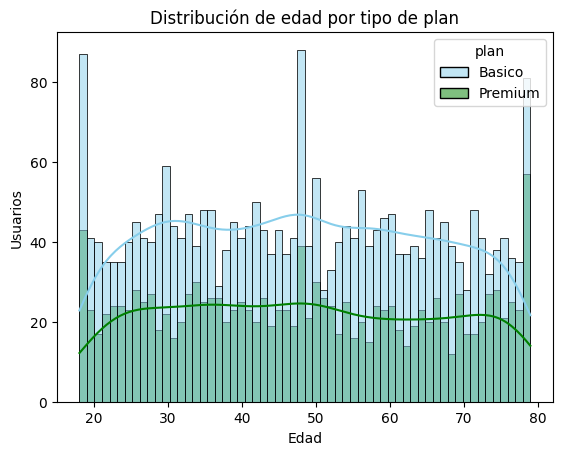

In [30]:

# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,x='age',bins=60,hue='plan',palette=['skyblue','green'],kde=True)

plt.xlabel("Edad")
plt.ylabel("Usuarios")
plt.title("Distribución de edad por tipo de plan")

plt.show()



💡Insights: 
- La distribución es similar entre ambos planes, por lo que se recomienda mantener las mismas estrategias.
- La distribución es aproximadamente simétrica, aunque hay picos en las barras, podrían deberse a una pequeña variación que en términos absolutos es un grupo pequeño.

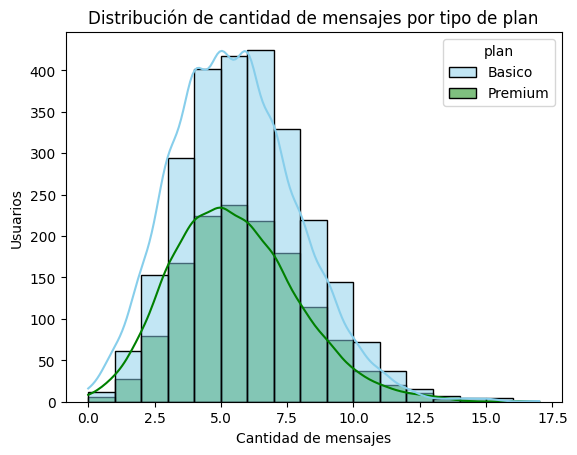

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile,x='cant_mensajes',bins=17,hue='plan',palette=['skyblue','green'],kde=True)

plt.xlabel('Cantidad de mensajes')
plt.ylabel('Usuarios')
plt.title('Distribución de cantidad de mensajes por tipo de plan')

plt.show()

💡Insights: 

- Los usuarios de ambos planes tienden a enviar entre 6 y 7 mensajes, si los mensajes no consumidos representan un costo se sugiere hacer un ajuste al total de mensajes incluidos.
- La distribución se ve ligeramente sesgada a la derecha, algunos usuarios realizan más mensajes pero no llegan a consumir los 100 y 500 que incluye el paquete.


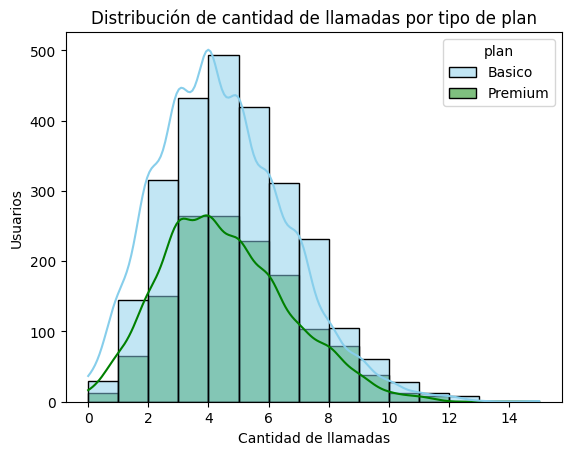

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,x='cant_llamadas',bins=15,hue='plan',palette=['skyblue','green'],kde=True)

plt.xlabel('Cantidad de llamadas')
plt.ylabel('Usuarios')
plt.title('Distribución de cantidad de llamadas por tipo de plan')

plt.show()

💡Insights: 
- Los usuarios de ambos planes tienden a realizar entre 4 y 6 llamadas, si las llamadas no consumidas representan un costo, se sugiere hacer un ajuste al total de llamadas incluidos.
- La distribución se ve ligeramente sesgada a la derecha.

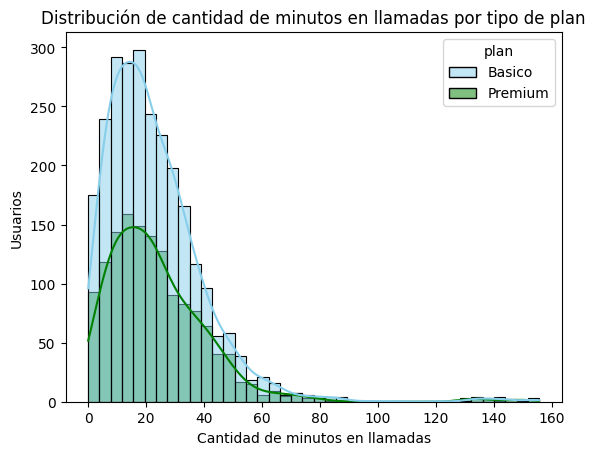

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,x='cant_minutos_llamada',bins=40,hue='plan',palette=['skyblue','green'],kde=True)

plt.xlabel('Cantidad de minutos en llamadas')
plt.ylabel('Usuarios')
plt.title('Distribución de cantidad de minutos en llamadas por tipo de plan')

plt.show()

💡Insights: 
- Los usuarios de ambos planes tienden a realizar entre llamadas de entre 16 a 20 minutos, si los minutos no consumidos representan un costo, se sugiere hacer un ajuste al total de minutos incluidos.
- La distribución tiene un sesgo a la derecha, lo cual indica comportamientos atipicos de algunos usuarios.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

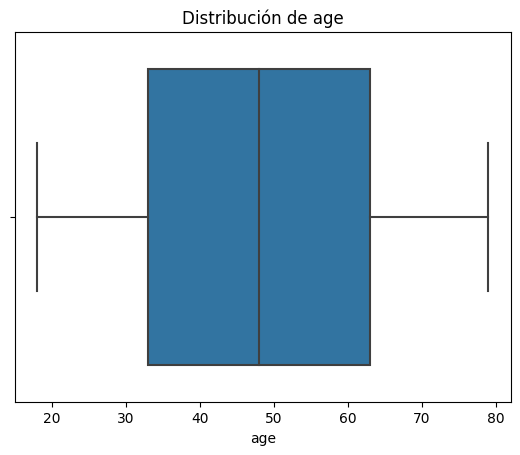

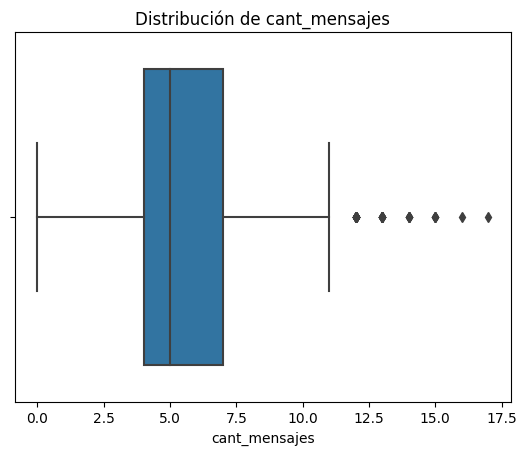

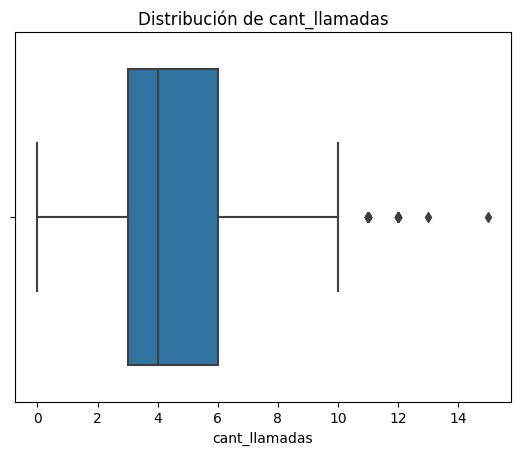

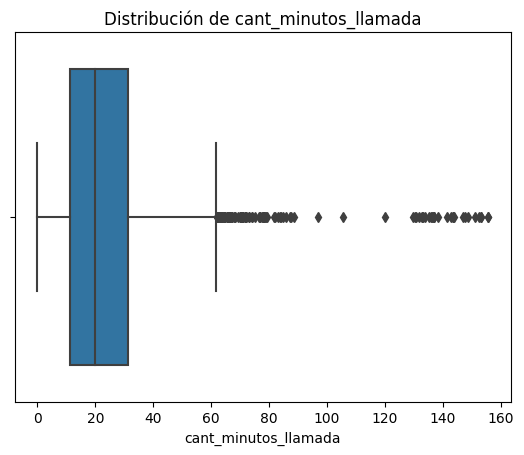

In [34]:


# Visualizando usando BoxPlot 

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
            sns.boxplot(data=user_profile,x=col)
    
            plt.title(f"Distribución de {col}")
            plt.show()




💡Insights: 
- Age: no presenta outliers
- cant_mensajes: presenta algunos outliers
- cant_llamadas: presenta algunos outliers
- cant_minutos_llamada: presenta bastantes outliers

In [35]:

# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:

            Q1 = user_profile[col].quantile(0.25)
            Q3 = user_profile[col].quantile(0.75)

            IQR = Q3 - Q1

            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR
            
            print(f"Q1 {col}:", Q1)
            print(f"Q3 {col}:", Q3)
            print(f"IQR {col}:", IQR)
            print(f"Límite inferior {col}:", lower)
            print(f"Límite superior {col}:", upper)
            print()

Q1 age: 33.0
Q3 age: 63.0
IQR age: 30.0
Límite inferior age: -12.0
Límite superior age: 108.0

Q1 cant_mensajes: 4.0
Q3 cant_mensajes: 7.0
IQR cant_mensajes: 3.0
Límite inferior cant_mensajes: -0.5
Límite superior cant_mensajes: 11.5

Q1 cant_llamadas: 3.0
Q3 cant_llamadas: 6.0
IQR cant_llamadas: 3.0
Límite inferior cant_llamadas: -1.5
Límite superior cant_llamadas: 10.5

Q1 cant_minutos_llamada: 11.12
Q3 cant_minutos_llamada: 31.415
IQR cant_minutos_llamada: 20.295
Límite inferior cant_minutos_llamada: -19.322500000000005
Límite superior cant_minutos_llamada: 61.8575



In [36]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.138285,5.524381,4.478120,23.317054
std,17.691541,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? - Sí mantener debido a que los outliers no están tan disparados para ensuciar el analisis
- cant_llamadas: mantener o no outliers, porqué? - Sí mantener debido a que los outliers no están tan disparados para ensuciar el analisis
- cant_minutos_llamada: mantener o no outliers, porqué? - No mantener ya que los outliers modifican la interpretación del analisis.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:

# Crear columna grupo_uso
user_profile['grupo_uso']= np.where((user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'Bajo uso',
                             np.where((user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'Uso medio','Alto uso'))


In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:

# Crear columna grupo_edad
user_profile['grupo_edad']= np.where(user_profile['age'] < 30, 'Joven',
                             np.where(user_profile['age'] < 60, 'Adulto','Adulto Mayor'))



In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

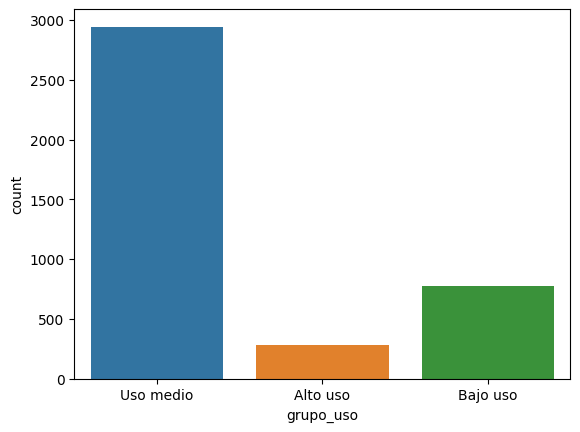

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')

plt.show()

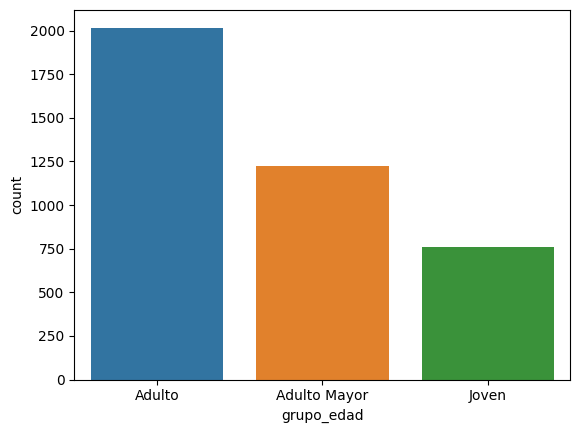

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- - Edad (age): se detectaron edades inválidas, como -999, que distorsionaban el promedio y la desviación estándar. Estos valores fueron reemplazados por la mediana calculada a partir de las edades válidas.
  - Ciudad (city): se encontraron 469 registros nulos (11.7% del total) y 96 registros adicionales con el valor inválido "?". En conjunto, representan 565 registros sin una ciudad válida (14.1%), lo que limita la precisión de futuros análisis geográficos.
  - Fecha de registro (reg_date): se identificaron 40 fechas posteriores a 2024 (1% de los registros), fuera del periodo establecido para el análisis. Estas fechas se marcaron como nulas.


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
- -  Se establecieron dos dimensiones de segmentación:
  -  Por edad: los usuarios se clasificaron en Joven (menores de 30 años), Adulto (30 a 59 años) y Adulto Mayor (60 años o más). El grupo Adulto concentra la mayor cantidad de usuarios, mientras que Joven presenta la menor participación.
  -  Por nivel de uso: se identificaron los grupos Bajo uso, Uso medio y Alto uso, a partir del número de llamadas y mensajes registrados. Uso medio representa el segmento más numeroso y Alto uso el menos frecuente.
  -  Adicionalmente, el análisis estadístico muestra un comportamiento de consumo moderado, con una mediana de 5 mensajes, 4 llamadas y aproximadamente 19.8 minutos acumulados por usuario.
       
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
- - Los segmentos Adulto y Uso medio destacan por concentrar la mayor cantidad de usuarios dentro de sus respectivas clasificaciones, lo que los convierte en grupos relevantes para las estrategias de retención y optimización comercial.
  - Adicionalmente, el plan Básico concentra aproximadamente el 64.9% de los usuarios analizados, frente al 35.1% del plan Premium. Esto sugiere que las iniciativas dirigidas a la base de clientes del plan Básico podrían tener un alcance importante.

 
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- - Se identificaron valores atípicos en la cantidad de mensajes, llamadas y, principalmente, en los minutos acumulados de llamadas.
  - En esta última variable, el consumo máximo alcanzó 155.69 minutos, frente a una mediana de 19.78 minutos. Además, el límite superior calculado mediante IQR fue de aproximadamente 61.86 minutos, lo que evidencia la presencia de usuarios con consumos considerablemente superiores a los habituales.


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
- - Evaluar la adecuación de los planes actuales: los usuarios presentan un consumo moderado de llamadas y mensajes, mientras que los planes Básico y Premium incluyen beneficios considerablemente superiores. Se recomienda comparar el consumo observado con las prestaciones de cada plan para identificar oportunidades de optimización, sin asumir que los beneficios no utilizados representan necesariamente un costo para la empresa.
  - Explorar un plan dirigido a adultos mayores: evaluar una oferta enfocada en llamadas y mensajes, considerando las necesidades de comunicación de este segmento. Antes de desarrollarla, sería necesario validar sus hábitos de consumo, preferencias y disposición de pago.






### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Durante la exploración inicial se identificaron inconsistencias en las variables age, city y reg_date, incluyendo edades inválidas, ciudades sin identificar y fechas de registro fuera del periodo de análisis, en particular, se detectaron 565 registros sin una ciudad válida (14.1% de los usuarios), lo que limita la precisión de los análisis geográficos.

- El tratamiento de estas inconsistencias permitió mejorar la calidad de la información y establecer una base más confiable para la segmentación de clientes.


🔍 **Segmentos por Edad**
- Los usuarios se clasificaron en tres grupos: Joven, Adulto y Adulto Mayor.
- El segmento Adulto concentra la mayor cantidad de clientes, mientras que el grupo Joven presenta la menor participación, esta distribución convierte al segmento Adulto en un grupo prioritario para profundizar en el análisis de comportamiento y evaluar estrategias comerciales de retención.


📊 **Segmentos por Nivel de Uso**
- Los clientes se clasificaron en Bajo uso, Uso medio y Alto uso, considerando sus registros de llamadas y mensajes.

El segmento Uso medio concentra la mayor cantidad de usuarios, mientras que Alto uso representa la menor proporción y se identificaron consumos extremos de hasta 155.69 minutos acumulados en llamadas, lo que evidencia diferencias importantes entre los hábitos de comunicación de los usuarios.


➡️ La concentración de clientes en los segmentos Adulto y Uso medio sugiere que el consumo moderado constituye un comportamiento relevante dentro de la base analizada.

Por otra parte, la existencia de usuarios con consumos significativamente superiores a los habituales indica que ConnectaTel atiende perfiles con distintas necesidades de comunicación.

Estos hallazgos representan una oportunidad para evaluar la adecuación de los planes actuales y profundizar en el comportamiento de cada segmento. Sin embargo, para determinar el valor comercial de los grupos será necesario incorporar indicadores de ingresos, rentabilidad y permanencia.


💡 **Recomendaciones**
- Evaluar los planes actuales: comparar los beneficios incluidos en los planes Básico y Premium con el consumo observado, utilizando periodos equivalentes para identificar posibles oportunidades de optimización.

- Profundizar en la segmentación: cruzar los grupos de edad y nivel de uso con el plan contratado para identificar patrones de consumo y oportunidades de retención.

- Explorar ofertas diferenciadas: investigar las necesidades de comunicación de los adultos mayores y evaluar la viabilidad de un plan enfocado en llamadas y mensajes.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`